# Calibração do modelo de Lotka-Volterra

O objetivo deste notebook é estudar a calibração dos parâmetros do modelo de Lotka-Volterra a partir de dados populacionais de presas e predadores.

Inicialmente, serão gerados dados sintéticos a partir de valores conhecidos dos parâmetros do modelo. Para isso, o sistema de equações diferenciais ordinárias será resolvido numericamente. Posteriormente, esses dados serão utilizados no processo de estimação dos parâmetros.

## Modelo de Lotka-Volterra

O modelo de Lotka-Volterra é dado por:

$$
\frac{dN}{dt} = \alpha N - \beta NP
$$

$$
\frac{dP}{dt} = \lambda NP - \gamma P
$$

em que:

- $N(t)$ representa a população de presas;
- $P(t)$ representa a população de predadores;
- $\alpha$ é a taxa de crescimento das presas;
- $\beta$ está relacionada à predação;
- $\lambda$ está relacionada ao crescimento dos predadores devido à predação;
- $\gamma$ é a taxa de mortalidade dos predadores.

## Imports

In [192]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.stats import qmc
from scipy.stats import gaussian_kde

## Preparando dados

### Definição dos parâmetros

In [193]:
alpha = 1.0
beta = 0.1
lambd = 0.075
gamma = 1.5

In [194]:
N0 = 10.0   # população inicial de presas
P0 = 5.0    # população inicial de predadores

### Definindo modelo e solução

In [195]:
def lotka_volterra(t, y, alpha, beta, lambd, gamma):

    N, P = y

    dNdt = alpha * N - beta * N * P
    dPdt = lambd * N * P - gamma * P

    return [dNdt, dPdt]

t0 = 0
tf = 30
t = np.linspace(t0, tf, 1000)

solucao = solve_ivp(
    lotka_volterra,
    [t0, tf],
    [N0, P0],
    t_eval=t,
    args=(alpha, beta, lambd, gamma)
)

# Solução para 1000 passos de tempo
N = solucao.y[0]
P = solucao.y[1]

### Amostrando dados e inserindo ruído

In [196]:
t_obs = t[::50] # 50 soluções amostradas uniformemente no tempo

sigma_N = 1.0 
sigma_P = 1.0

rng_dados = np.random.default_rng(2026)

N_obs = N[::50] + rng_dados.normal(0, sigma_N, size=t_obs.size)
P_obs = P[::50] + rng_dados.normal(0, sigma_P, size=t_obs.size)

### Observando plot dos dados da solução numérica com os parâmetros reais e os amostrados com ruídos

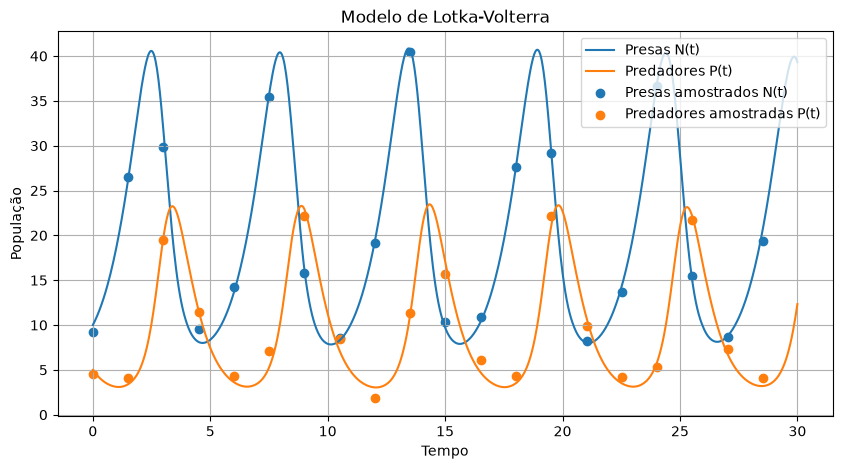

In [197]:
plt.figure(figsize=(10, 5))

plt.plot(t, N, label='Presas N(t)')
plt.plot(t, P, label='Predadores P(t)')
plt.scatter(t_obs, N_obs, label='Presas amostrados N(t)')
plt.scatter(t_obs, P_obs, label='Predadores amostradas P(t)')

plt.xlabel('Tempo')
plt.ylabel('População')
plt.title('Modelo de Lotka-Volterra')
plt.legend()
plt.grid()

plt.show()

## Fazendo calibração dos parâmetros com aprendizagem bayseana

### Definindo distribuições a priori

In [198]:
nomes_parametros = ['alpha', 'beta', 'lambd', 'gamma']

# limite_inferior = np.array([0.5, 0.05, 0.03, 1.0])
# limite_superior = np.array([1.5, 0.15, 0.12, 2.0])
limite_inferior = np.array([0.0, 0.0, 0.01, 0.0])
limite_superior = np.array([20.0, 20.0, 20.0, 20.0])

### Definindo cálculo da posteriori

In [199]:
def posterior_parametros(parametros):

    alpha_proposto, beta_proposto, lambd_proposto, gamma_proposto = parametros

    # =========================================================
    # Priori uniforme
    # =========================================================

    if np.any(parametros < limite_inferior) or np.any(parametros > limite_superior):
        return 0.0

    # =========================================================
    # Resolve Lotka-Volterra
    # =========================================================

    solucao_proposta = solve_ivp(lotka_volterra, [t0, tf], [N0, P0], t_eval=t_obs, args=(alpha_proposto, beta_proposto, lambd_proposto, gamma_proposto))

    if (
        not solucao_proposta.success
        or solucao_proposta.y.shape[1] != t_obs.size
    ):
        return 0.0

    N_modelo, P_modelo = solucao_proposta.y

    # =========================================================
    # Likelihood das presas
    # =========================================================

    # likelihood_N = np.prod((1 / (sigma_N * np.sqrt(2 * np.pi)))* np.exp(-0.5 * ((N_obs - N_modelo) / sigma_N) ** 2))
    likelihood_N = np.prod((1 / (sigma_N * np.sqrt(2 * np.pi)))* np.exp(-0.5 * ((N_obs - N_modelo) / N_modelo*sigma_N) ** 2))

    # =========================================================
    # Likelihood dos predadores
    # =========================================================

    # likelihood_P = np.prod((1 / (sigma_P * np.sqrt(2 * np.pi)))* np.exp(-0.5 * ((P_obs - P_modelo) / sigma_P) ** 2))
    likelihood_P = np.prod((1 / (sigma_P * np.sqrt(2 * np.pi)))* np.exp(-0.5 * ((P_obs - P_modelo) / P_modelo*sigma_P) ** 2))

    # =========================================================
    # Priori uniforme
    # =========================================================

    largura = limite_superior - limite_inferior

    priori = np.prod(1 / largura)

    # =========================================================
    # Posteriori não normalizada
    # =========================================================

    posteriori = likelihood_N * likelihood_P * priori

    return posteriori

### Definindo cadeia inicial usando Sobel

Definindo função de erro minimos quadrados

In [200]:
# def erro_minimos_quadrados(parametros):

#     alpha, beta, lambd, gamma = parametros

#     solucao = solve_ivp(
#         lotka_volterra,
#         [t0, tf],
#         [N0, P0],
#         t_eval=t_obs,
#         args=(alpha, beta, lambd, gamma)
#     )

#     if (
#         not solucao.success
#         or solucao.y.shape[1] != len(t_obs)
#     ):
#         return np.inf

#     N_modelo, P_modelo = solucao.y

#     erro_N = np.sum((N_obs - N_modelo) ** 2)
#     erro_P = np.sum((P_obs - P_modelo) ** 2)

#     return erro_N + erro_P

def erro_minimos_quadrados(parametros):

    alpha, beta, lambd, gamma = parametros

    solucao = solve_ivp(
        lotka_volterra,
        [t0, tf],
        [N0, P0],
        t_eval=t_obs,
        args=(alpha, beta, lambd, gamma)
    )

    if (
        not solucao.success
        or solucao.y.shape[1] != len(t_obs)
    ):
        return np.inf

    N_modelo, P_modelo = solucao.y

    erro_N = np.mean((N_obs - N_modelo) ** 2)
    erro_P = np.mean((P_obs - P_modelo) ** 2)

    return erro_N + erro_P

Sorteando espaço paramétrico e testando qual o melhor:

In [ ]:
# 2^8 = 256 pontos no espaço paramétrico
m = 8

sobol = qmc.Sobol(
    d=4,
    scramble=True,
    seed=2026
)

pontos_unitarios = sobol.random_base2(m=m)

pontos_parametros = qmc.scale(
    pontos_unitarios,
    limite_inferior,
    limite_superior
)

erros = np.array([
    erro_minimos_quadrados(p)
    for p in pontos_parametros
])

indice_melhor = np.argmin(erros)

parametros_iniciais = pontos_parametros[indice_melhor]

print("Ponto inicial escolhido:")
print(f"alpha  = {parametros_iniciais[0]:.6f}")
print(f"beta   = {parametros_iniciais[1]:.6f}")
print(f"lambda = {parametros_iniciais[2]:.6f}")
print(f"gamma  = {parametros_iniciais[3]:.6f}")

print("\nErro de mínimos quadrados:")
print(erros[indice_melhor])

### Definindo desvio padrão da distrbuição de visitação

Definindo função para executar modelo (calcular solução) e calcular a matriz de sensibilidade

In [ ]:
def executar_modelo(parametros):

    alpha, beta, lambd, gamma = parametros

    solucao = solve_ivp(
        lotka_volterra,
        [t0, tf],
        [N0, P0],
        t_eval=t_obs,
        args=(alpha, beta, lambd, gamma)
    )

    if not solucao.success:
        return None

    N_modelo, P_modelo = solucao.y

    return np.concatenate([
        N_modelo,
        P_modelo
    ])

def matriz_sensibilidade(parametros, passo_relativo=1e-5):

    parametros = np.asarray(parametros, dtype=float)
    
    y0 = executar_modelo(parametros)

    n_saidas = len(y0)
    n_parametros = len(parametros)

    J = np.zeros((n_saidas, n_parametros))

    for j in range(n_parametros):

        passo = passo_relativo * max(abs(parametros[j]), 1.0)

        parametros_mais = parametros.copy()
        parametros_menos = parametros.copy()

        parametros_mais[j] += passo
        parametros_menos[j] -= passo

        y_mais = executar_modelo(parametros_mais)
        y_menos = executar_modelo(parametros_menos)

        J[:, j] = (
            y_mais - y_menos
        ) / (2 * passo)

    return J

Calculando a matriz de sensibilidade e determinando delta da distribuição de visitação

In [ ]:
J = matriz_sensibilidade(parametros_iniciais)

n_obs = len(t_obs)

J_normalizado = J.copy()

J_normalizado[:n_obs, :] /= sigma_N
J_normalizado[n_obs:, :] /= sigma_P

informacao = J_normalizado.T @ J_normalizado

covariancia_inicial = np.linalg.pinv(informacao)

desvios_proposta = np.sqrt(
    np.diag(covariancia_inicial)
)

print("Desvios-padrão estimados:")
print(f"alpha  = {desvios_proposta[0]:.6f}")
print(f"beta   = {desvios_proposta[1]:.6f}")
print(f"lambda = {desvios_proposta[2]:.6f}")
print(f"gamma  = {desvios_proposta[3]:.6f}")

Desvios-padrão estimados:
alpha  = 0.426528
beta   = 0.064385
lambda = 0.042520
gamma  = 0.508620


### Executando algoritmo de Metropolis-Hastings (corrigir: tirar log)

#### Parâmetros

In [ ]:
rng = np.random.default_rng(2026)

n_iteracoes = 50000
burn_in = 0

#### Algoritmo

In [ ]:
cadeia = np.empty((n_iteracoes, 4))

parametros_atuais = parametros_iniciais.copy()

posterior_atual = posterior_parametros(
    parametros_atuais
)

covariancia_proposta = covariancia_inicial.copy()

# Históricos
erros = []
historico_aceitacao = []

aceitos = 0

# Dimensão do problema
d = 4

# Fator de escala da covariância
sp = (2.38 ** 2) / d

# Pequeno valor para evitar matriz singular
epsilon = 1e-8

# Iteração a partir da qual começa a adaptação
k0 = 100


for iteracao in range(n_iteracoes):

    # =========================================================
    # 1. Atualização adaptativa da covariância
    # =========================================================

    if iteracao >= k0 and iteracao % 100 == 0:

        covariancia_amostral = np.cov(
            cadeia[:iteracao],
            rowvar=False
        )

        covariancia_proposta = (
            sp * covariancia_amostral
            + epsilon * np.eye(d)
        )

    # =========================================================
    # 2. Geração do candidato
    # =========================================================

    parametros_propostos = rng.multivariate_normal(
        parametros_atuais,
        covariancia_proposta
    )

    # =========================================================
    # 3. Calcula posteriori do candidato
    # =========================================================

    posterior_proposta = posterior_parametros(
        parametros_propostos
    )

    # =========================================================
    # 4. Probabilidade de aceitação
    # =========================================================

    if posterior_atual == 0:

        if posterior_proposta > 0:
            alpha_mh = 1.0
        else:
            alpha_mh = 0.0

    else:

        alpha_mh = min(
            1.0,
            posterior_proposta / posterior_atual
        )

    # =========================================================
    # 5. Aceita ou rejeita
    # =========================================================

    if rng.uniform() < alpha_mh:

        parametros_atuais = parametros_propostos
        posterior_atual = posterior_proposta

        aceitos += 1

    # =========================================================
    # 6. Armazena o estado atual
    # =========================================================

    cadeia[iteracao] = parametros_atuais

    # =========================================================
    # 7. Taxa de aceitação acumulada
    # =========================================================

    taxa_atual = aceitos / (iteracao + 1)

    historico_aceitacao.append(
        taxa_atual
    )

    # =========================================================
    # 8. Erro de mínimos quadrados
    # =========================================================

    erro_atual = erro_minimos_quadrados(
        parametros_atuais
    )

    erros.append(
        erro_atual
    )


# =========================================================
# Resultado final
# =========================================================

taxa_aceitacao = aceitos / n_iteracoes

print(
    f"Taxa final de aceitação: "
    f"{taxa_aceitacao:.3f}"
)

Taxa final de aceitação: 0.028


## Observando resultados

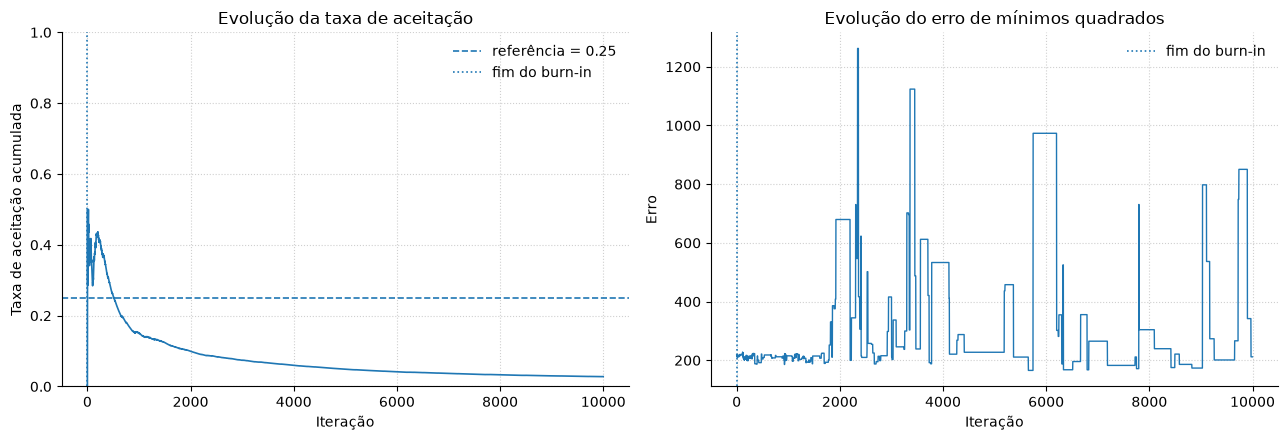

In [ ]:
fig, eixos = plt.subplots(
    1, 2,
    figsize=(13, 4.5)
)

# =========================================================
# Taxa de aceitação
# =========================================================

eixos[0].plot(
    historico_aceitacao,
    linewidth=1.2
)

eixos[0].axhline(
    0.25,
    linestyle='--',
    linewidth=1.2,
    label='referência = 0.25'
)

eixos[0].axvline(
    burn_in,
    linestyle=':',
    linewidth=1.2,
    label='fim do burn-in'
)

eixos[0].set(
    title='Evolução da taxa de aceitação',
    xlabel='Iteração',
    ylabel='Taxa de aceitação acumulada'
)

eixos[0].set_ylim(0, 1)

eixos[0].grid(
    linestyle=':',
    alpha=0.6
)

eixos[0].legend(
    frameon=False
)


# =========================================================
# Erro
# =========================================================

eixos[1].plot(
    erros,
    linewidth=1
)

eixos[1].axvline(
    burn_in,
    linestyle=':',
    linewidth=1.2,
    label='fim do burn-in'
)

eixos[1].set(
    title='Evolução do erro de mínimos quadrados',
    xlabel='Iteração',
    ylabel='Erro'
)

eixos[1].grid(
    linestyle=':',
    alpha=0.6
)

eixos[1].legend(
    frameon=False
)

# Limpeza visual
for eixo in eixos:
    eixo.spines['top'].set_visible(False)
    eixo.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

### Observando média e intervalo (com determinada metodologia) observado

In [ ]:
amostras_posteriores = cadeia[burn_in:, :]

media_posterior = amostras_posteriores.mean(axis=0)

intervalos_credibilidade = np.quantile(
    amostras_posteriores,
    [0.025, 0.975],
    axis=0
)

for indice, nome in enumerate(nomes_parametros):
    print(
        f'{nome}: média={media_posterior[indice]:.5f}, '
        f'ICr 95%=[{intervalos_credibilidade[0, indice]:.5f}, '
        f'{intervalos_credibilidade[1, indice]:.5f}]'
    )

alpha: média=4.73825, ICr 95%=[4.03675, 4.96627]
beta: média=0.30954, ICr 95%=[0.19181, 0.65135]
lambd: média=0.55959, ICr 95%=[0.32194, 0.79878]
gamma: média=4.81054, ICr 95%=[4.52308, 4.99188]


### Plotando a visitação, a média e a distribuição marginal obtida para cada parâmetro (corrigir para código corresponder)

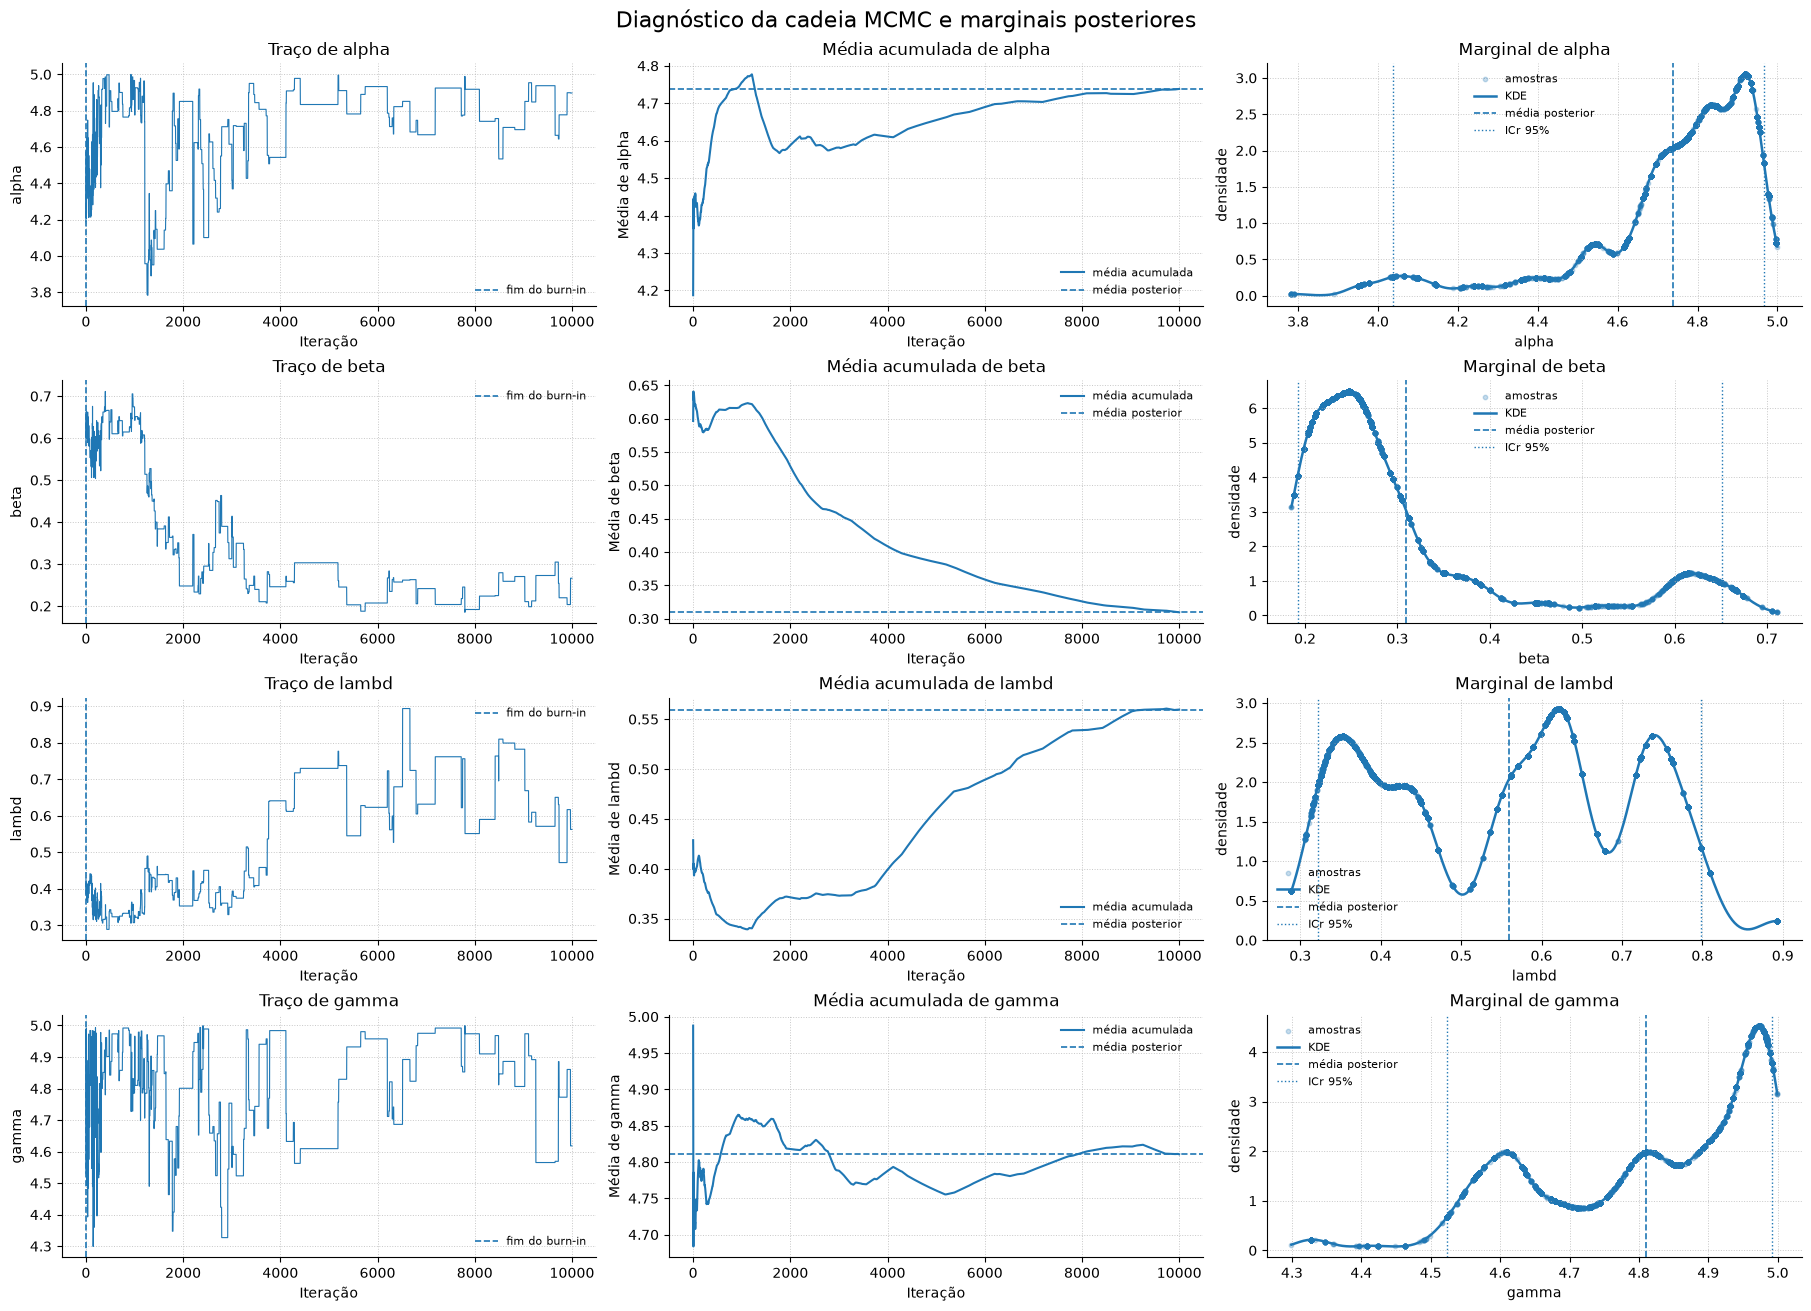

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

fig, eixos = plt.subplots(4, 3, figsize=(18, 13), constrained_layout=True)

fig.suptitle(
    'Diagnóstico da cadeia MCMC e marginais posteriores',
    fontsize=16
)

for indice, nome in enumerate(nomes_parametros):

    eixo_traco = eixos[indice, 0]
    eixo_media = eixos[indice, 1]
    eixo_marginal = eixos[indice, 2]

    # =========================================================
    # Configurações visuais comuns
    # =========================================================

    for ax in (eixo_traco, eixo_media, eixo_marginal):
        ax.grid(True, linestyle=':', linewidth=0.7, alpha=0.7)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

    # =========================================================
    # 1. Traço da cadeia
    # =========================================================

    eixo_traco.plot(
        cadeia[:, indice],
        linewidth=0.8
    )

    eixo_traco.axvline(
        burn_in,
        linestyle='--',
        linewidth=1.2,
        label='fim do burn-in'
    )

    eixo_traco.set_title(f'Traço de {nome}', fontsize=12)
    eixo_traco.set_xlabel('Iteração')
    eixo_traco.set_ylabel(nome)
    eixo_traco.legend(fontsize=8, frameon=False)

    # =========================================================
    # 2. Média acumulada pós-burn-in
    # =========================================================

    valores_pos_burnin = cadeia[burn_in:, indice]

    media_acumulada = np.cumsum(valores_pos_burnin) / np.arange(
        1, len(valores_pos_burnin) + 1
    )

    iteracoes_pos_burnin = np.arange(burn_in, len(cadeia))

    eixo_media.plot(
        iteracoes_pos_burnin,
        media_acumulada,
        linewidth=1.5,
        label='média acumulada'
    )

    eixo_media.axhline(
        media_posterior[indice],
        linestyle='--',
        linewidth=1.2,
        label='média posterior'
    )

    eixo_media.set_title(f'Média acumulada de {nome}', fontsize=12)
    eixo_media.set_xlabel('Iteração')
    eixo_media.set_ylabel(f'Média de {nome}')
    eixo_media.legend(fontsize=8, frameon=False)

    # =========================================================
    # 3. Marginal posterior: pontos + KDE
    # =========================================================

    amostras = amostras_posteriores[:, indice]

    kde = gaussian_kde(amostras)

    # altura da densidade nos próprios pontos
    densidades = kde(amostras)

    # grade suave para a curva KDE
    x_grid = np.linspace(amostras.min(), amostras.max(), 400)
    y_grid = kde(x_grid)

    ic_inferior = intervalos_credibilidade[0, indice]
    ic_superior = intervalos_credibilidade[1, indice]

    eixo_marginal.scatter(
        amostras,
        densidades,
        s=10,
        alpha=0.25,
        label='amostras'
    )

    eixo_marginal.plot(
        x_grid,
        y_grid,
        linewidth=1.8,
        label='KDE'
    )

    eixo_marginal.axvline(
        media_posterior[indice],
        linestyle='--',
        linewidth=1.2,
        label='média posterior'
    )

    eixo_marginal.axvline(
        ic_inferior,
        linestyle=':',
        linewidth=1.0,
        label='ICr 95%'
    )

    eixo_marginal.axvline(
        ic_superior,
        linestyle=':',
        linewidth=1.0
    )

    eixo_marginal.set_title(f'Marginal de {nome}', fontsize=12)
    eixo_marginal.set_xlabel(nome)
    eixo_marginal.set_ylabel('densidade')
    eixo_marginal.legend(fontsize=8, frameon=False)

plt.show()

### Plotando ajuste obtido em comparação com o real e as amostras observadas

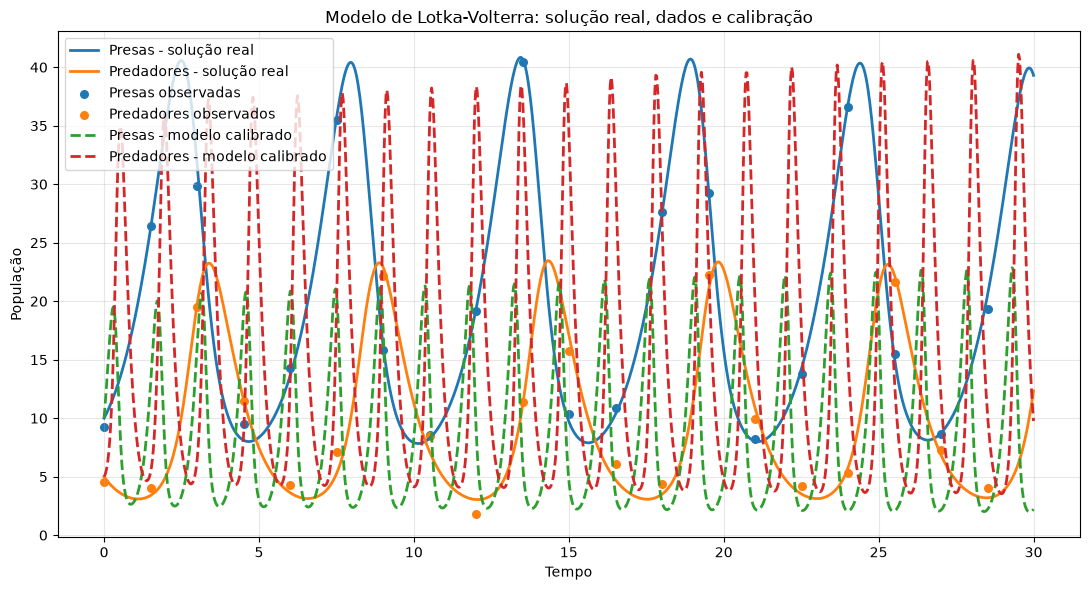

In [ ]:
solucao_posterior = solve_ivp(
    lotka_volterra,
    [t0, tf],
    [N0, P0],
    t_eval=t,
    args=tuple(media_posterior)
)

N_ajustado = solucao_posterior.y[0]
P_ajustado = solucao_posterior.y[1]


plt.figure(figsize=(11, 6))

# Curvas reais usadas para gerar os dados
plt.plot(
    t, N,
    label='Presas - solução real',
    linewidth=2
)

plt.plot(
    t, P,
    label='Predadores - solução real',
    linewidth=2
)

# Dados observados
plt.scatter(
    t_obs, N_obs,
    label='Presas observadas',
    s=30
)

plt.scatter(
    t_obs, P_obs,
    label='Predadores observados',
    s=30
)

# Solução usando os parâmetros estimados pelo MCMC
plt.plot(
    t, N_ajustado,
    '--',
    label='Presas - modelo calibrado',
    linewidth=2
)

plt.plot(
    t, P_ajustado,
    '--',
    label='Predadores - modelo calibrado',
    linewidth=2
)

plt.xlabel('Tempo')
plt.ylabel('População')
plt.title('Modelo de Lotka-Volterra: solução real, dados e calibração')

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()